In [4]:
link1 = "https://www.youtube.com/watch?v=eUnVZCtpUcM"
link_id1 = link1.split("=")
print(link_id1)
link_id2 = link_id1[1]
print(link_id2)

['https://www.youtube.com/watch?v', 'eUnVZCtpUcM']
eUnVZCtpUcM


In [130]:
import pandas as pd
df = pd.read_csv("SuperMarket Analysis.csv")
df.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Sales,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,1:08:00 PM,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29:00 AM,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,1:23:00 PM,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,8:33:00 PM,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37:00 AM,Ewallet,604.17,4.761905,30.2085,5.3


In [52]:
time1 = df ["Time"]
time_max = time1.max()
time_min = time1.min()
print("Max time:",time_max)
print("Min time:",time_min)

Max time: 8:59:00 PM
Min time: 10:00:00 AM


In [55]:
earliest_am = []
latest_pm = []
cluster1 = []
cluster2 = []
cluster3 = []
cluster4 = []
cluster5 = []

for x in time1:
    y = x.split(" ")
    y1 = y[0]
    ampm = y[1]
    y2 = y1.split(":")
    hour = y2[0]
    hour = int(hour)
    minute = y2[0]
    if ampm == "AM": 
        earliest_am.append(hour)
        hour_int = int(hour)
        if 10 <= hour_int < 12:
            cluster1.append(hour_int)
        
    elif ampm == "PM":
        latest_pm.append(hour)
        hour_int = int(hour)
        if 12 <= hour_int < 2:
            cluster2.append(hour_int)
        elif 2 <= hour < 4:
            cluster3.append(hour_int)
        elif 4 <= hour < 6:
            cluster4.append(hour_int)
        elif 6 <= hour < 8:
            cluster5.append(hour_int)  

In [56]:
print(len(cluster1))
print(len(cluster2))
print(len(cluster3))
print(len(cluster4))
print(len(cluster5))

191
0
185
151
206


In [57]:
import matplotlib.pyplot as plt

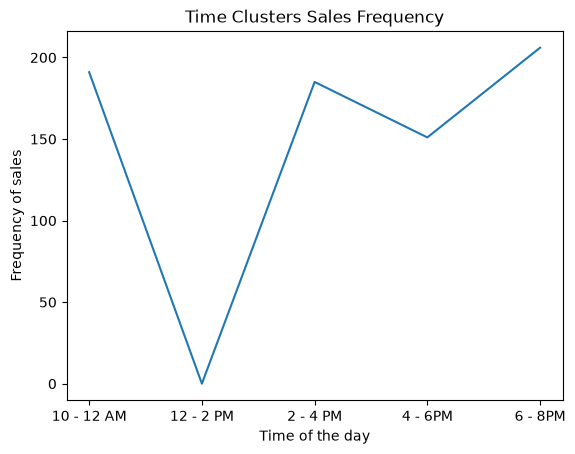

In [58]:
time_of_day = [len(cluster1),len(cluster2),len(cluster3),len(cluster4),len(cluster5)]
time_labels = ["10 - 12 AM", "12 - 2 PM", "2 - 4 PM", "4 - 6PM", "6 - 8PM"]

plt.plot(time_labels,time_of_day)
plt.xlabel("Time of the day")
plt.ylabel("Frequency of sales")
plt.title("Time Clusters Sales Frequency")
plt.show()

In [67]:
#==========================================================================
# Sales and Revenue Analysis
#==========================================================================
# Identify top-selling product lines by revenue and quantity.
sales = df["Sales"]
product = df["Product line"]
quantity = df["Quantity"]
productqsales = list(zip(sales,product,quantity))
#print(productqsales)

product_revenue = {}
product_quantity = {}

for sales_val,product_name,qty_val in productqsales:
    if product_name in product_revenue:
        product_revenue[product_name] += sales_val
        product_quantity[product_name] += qty_val
    else:
        product_revenue[product_name] = sales_val
        product_quantity[product_name] = qty_val
#product with max revenue
top_rev_product = max(product_revenue,key = product_revenue.get)
top_qty_product = max(product_quantity,key = product_quantity.get)

print ("Top Revenue Product :", top_rev_product)
print ("Top Quantity Product :", top_qty_product)

Top Revenue Product : Food and beverages
Top Quantity Product : Electronic accessories


In [74]:
#Calculate average transaction value per branch
branch = df["Branch"]
branchsales = list(zip(branch,sales))

salesbranch = {}
branchcounts = {}

for branch,sales_val in branchsales:
    if branch in salesbranch:
        salesbranch[branch] += sales_val
        branchcounts[branch] += 1
    else:
        salesbranch[branch] = sales_val
        branchcounts[branch] = 1
for branch in salesbranch:
    avg_value = salesbranch[branch]/branchcounts[branch]
    print(f"Branch {branch} Average Transaction Value: {avg_value:}")

Branch Alex Average Transaction Value: 312.35403088235324
Branch Giza Average Transaction Value: 337.09971493902424
Branch Cairo Average Transaction Value: 319.87250602409625


In [81]:
#Gross Income between Branches
branch = df["Branch"]
income = df["gross income"]
branchincome = list(zip(branch,income))
branch_income = {}

for branch_name,income_val in branchincome:
    if branch_name in branch_income:
        branch_income[branch_name] += income_val
    else:
        branch_income[branch_name] = income_val
for branch_name, total_income in branch_income.items():
    print(f"Branch {branch_name} Total Gross Income: {total_income}")

Branch Alex Total Gross Income: 5057.160500000002
Branch Giza Total Gross Income: 5265.176500000002
Branch Cairo Total Gross Income: 5057.032000000003


In [91]:
#Peak sales by date and time
dates = df["Date"]
times = df ["Time"]
sales = df["Sales"]
date_sales = list(zip(dates,sales))
time_sales = list(zip(times,sales))

sales_dates = {}
sales_time = {}

for d,s in date_sales:
    if d in sales_dates:
        sales_dates[d] += s
    else:
        sales_dates[d] = s
for t,s in time_sales:
    y = t.split(" ")
    y1 = y[0]
    ampm = y[1]
    y2 = y1.split(":")
    hour = y2[0]
    hour = int(hour)
    if hour in sales_time:
        sales_time[hour] += s
    else:
        sales_time[hour] = s
    
peak_date = max(sales_dates, key = sales_dates.get)
peak_time = max(sales_time, key = sales_time.get)

print(f"Peak Sales Date : {peak_date} ({sales_dates[peak_date]})")
print(f"Peak Sales Time : {peak_time}{ampm} ({sales_time[peak_time]})")

Peak Sales Date : 3/9/2019 (7474.0470000000005)
Peak Sales Time : 7PM (39699.51300000002)


In [102]:
#Compare spending habits between Members and Normal customers.
customer_type = df["Customer type"]
sales = df["Sales"]
quantity = df["Quantity"]
customersinfo = list(zip(customer_type, quantity, sales))

sales_c = {}
quantity_c = {}
counts_type = {}

for customer, q, s in customersinfo:
    if customer in sales_c:
        sales_c[customer] += s
        quantity_c[customer] += q
        counts_type[customer] += 1
    else:
        sales_c[customer] = s
        quantity_c[customer] = q
        counts_type[customer] = 1
        
#Averages for ALL customer types
for customer in sales_c:
    total_revenue = sales_c[customer]
    total_quantity = quantity_c[customer]
    count = counts_type[customer]

    average_revenue = total_revenue / count
    average_quantity = total_quantity / count

    print(f"\nCustomer type: {customer}")
    print(f"Average Transactions   : {average_revenue}")
    print(f"Average Items Quantity : {average_quantity}")


Customer type: Member
Average Transactions   : 335.7429451327431
Average Items Quantity : 5.6300884955752215

Customer type: Normal
Average Transactions   : 306.3723793103448
Average Items Quantity : 5.354022988505747


In [106]:
#Compare purchase frequency by gender.
gender = df["Gender"]
sales = df["Sales"]
genderinfo = list(zip(gender,sales))

gender_counts = {}
gender_sales = {}

for g, s in genderinfo:
    if g in gender_counts:
        gender_counts[g] += 1
        gender_sales[g] += s
    else:
        gender_counts[g] = 1
        gender_sales[g] = s
total_transactions = len(genderinfo)

# Comparison
for g in gender_counts:
    count = gender_counts[g]
    total_spend = gender_sales[g]
    avg_spend = total_spend / count

    print(f"\nGender: {g}")
    print(f"  Total Purchases (Frequency) : {count}")
    print(f"  Average Spend per Purchase  : ${avg_spend}")



Gender: Female
  Total Purchases (Frequency) : 571
  Average Spend per Purchase  : $340.9314141856393

Gender: Male
  Total Purchases (Frequency) : 429
  Average Spend per Purchase  : $299.0557377622379


In [107]:
#Analyze rating patterns and their relation to product lines
product_line = df["Product line"]
rating = df["Rating"]

product_rate = list(zip(product_line, rating))

prod_rating_sum = {}
prod_rating_count = {}

for prod, r in product_rate:
    if prod in prod_rating_sum:
        prod_rating_sum[prod] += r
        prod_rating_count[prod] += 1
    else:
        prod_rating_sum[prod] = r
        prod_rating_count[prod] = 1

#print("=== Rating Analysis by Product Line ===")
for prod in prod_rating_sum:
    avg_rating = prod_rating_sum[prod] / prod_rating_count[prod]
    count = prod_rating_count[prod]
    print(f"\nProduct Line : {prod}")
    print(f"  Total Reviews : {count}")
    print(f"  Average Rating: {avg_rating:.2f} / 10")


Product Line : Health and beauty
  Total Reviews : 152
  Average Rating: 7.00 / 10

Product Line : Electronic accessories
  Total Reviews : 170
  Average Rating: 6.92 / 10

Product Line : Home and lifestyle
  Total Reviews : 160
  Average Rating: 6.84 / 10

Product Line : Sports and travel
  Total Reviews : 166
  Average Rating: 6.92 / 10

Product Line : Food and beverages
  Total Reviews : 174
  Average Rating: 7.11 / 10

Product Line : Fashion accessories
  Total Reviews : 178
  Average Rating: 7.03 / 10


In [112]:
#Most popular payment method by transaction count.
payment = df["Payment"]

payment_counts = {}

for p in payment:
    if p in payment_counts:
        payment_counts[p] += 1
    else:
        payment_counts[p] = 1

popular_payment = max(payment_counts, key=payment_counts.get)
top_count = payment_counts[popular_payment]
total_transactions = len(payment)

for p, count in payment_counts.items():
    pct = (count / total_transactions) * 100
    print(f"{p}: {count} transactions")

print(
    f"Most Popular: {popular_payment}: {top_count} transactions ({(top_count / total_transactions) * 100}%)"
)

Ewallet: 345 transactions
Cash: 344 transactions
Credit card: 311 transactions
Most Popular: Ewallet: 345 transactions (34.5%)


In [115]:
#Average transaction values by payment method.
payment = df["Payment"]
sales = df["Sales"]

payment_salesinfo = list(zip(payment, sales))

payment_totals = {}
payment_counts = {}

for p, s in payment_salesinfo:
    if p in payment_totals:
        payment_totals[p] += s
        payment_counts[p] += 1
    else:
        payment_totals[p] = s
        payment_counts[p] = 1

print("=== Average Transaction Value by Payment Method ===")
for p in payment_totals:
    total_sales = payment_totals[p]
    count = payment_counts[p]
    avg_transaction = total_sales / count

    print(f"\nPayment Method: {p}")
    print(f"  Total Revenue        : ${total_sales}")
    print(f"  Total Transactions   : {count}")
    print(f"  Average transaction : ${avg_transaction}")

=== Average Transaction Value by Payment Method ===

Payment Method: Ewallet
  Total Revenue        : $109993.107
  Total Transactions   : 345
  Average transaction : $318.8206

Payment Method: Cash
  Total Revenue        : $112206.56999999995
  Total Transactions   : 344
  Average transaction : $326.18188953488357

Payment Method: Credit card
  Total Revenue        : $100767.07200000006
  Total Transactions   : 311
  Average transaction : $324.009877813505


In [121]:
#payment method distribution across branches
branch = df["Branch"]
payment = df["Payment"]

branch_payment = list(zip(branch, payment))

branch_payment_counts = {}
branch_totals = {}

for b, p in branch_payment:
    if b in branch_totals:
        branch_totals[b] += 1
    else:
        branch_totals[b] = 1
    if b not in branch_payment_counts:###***?
        branch_payment_counts[b] = {}
        
    if p in branch_payment_counts[b]:
        branch_payment_counts[b][p] += 1
    else:
        branch_payment_counts[b][p] = 1

# Payment distribution for each branch
for b in branch_payment_counts:
    total = branch_totals[b]
    print(f"\nBranch {b} (Total Transactions: {total}):")

    for p, count in branch_payment_counts[b].items():
        percentage = (count / total) * 100
        print(f"  {p}: {count} transactions ({percentage:.2f}%)")


Branch Alex (Total Transactions: 340):
  Ewallet: 126 transactions (37.06%)
  Credit card: 104 transactions (30.59%)
  Cash: 110 transactions (32.35%)

Branch Giza (Total Transactions: 328):
  Cash: 124 transactions (37.80%)
  Ewallet: 106 transactions (32.32%)
  Credit card: 98 transactions (29.88%)

Branch Cairo (Total Transactions: 332):
  Credit card: 109 transactions (32.83%)
  Ewallet: 113 transactions (34.04%)
  Cash: 110 transactions (33.13%)


In [123]:
#Calculate profit margins per product line.
product_line = df["Product line"]
sales = df["Sales"]
gross_income = df["gross income"]  # profit

product_profitinfo = list(zip(product_line, sales, gross_income))

product_sales = {}
product_profit = {}

for prod, s, profit in product_profitinfo:
    if prod in product_sales:
        product_sales[prod] += s
        product_profit[prod] += profit
    else:
        product_sales[prod] = s
        product_profit[prod] = profit

print("Profit Margin Analysis by Product Line")
for prod in product_sales:
    total_rev = product_sales[prod]
    total_prof = product_profit[prod]

    # Profit Margin (Total Profit / Total Sales) * 100
    profit_margin_pct = (total_prof / total_rev) * 100

    print(f"\nProduct Line : {prod}")
    print(f"  Total Sales   : ${total_rev:,.2f}")
    print(f"  Total Profit  : ${total_prof:,.2f}")
    print(f"  Profit Margin : {profit_margin_pct:.2f}%")

=== Profit Margin Analysis by Product Line ===

Product Line : Health and beauty
  Total Sales   : $49,193.74
  Total Profit  : $2,342.56
  Profit Margin : 4.76%

Product Line : Electronic accessories
  Total Sales   : $54,337.53
  Total Profit  : $2,587.50
  Profit Margin : 4.76%

Product Line : Home and lifestyle
  Total Sales   : $53,861.91
  Total Profit  : $2,564.85
  Profit Margin : 4.76%

Product Line : Sports and travel
  Total Sales   : $55,122.83
  Total Profit  : $2,624.90
  Profit Margin : 4.76%

Product Line : Food and beverages
  Total Sales   : $56,144.84
  Total Profit  : $2,673.56
  Profit Margin : 4.76%

Product Line : Fashion accessories
  Total Sales   : $54,305.89
  Total Profit  : $2,585.99
  Profit Margin : 4.76%


In [127]:
#Most profitable product line and branch.
product_line = df["Product line"]
branch = df["Branch"]
gross_income = df["gross income"]  # profit
Products_income = list(zip(product_line, gross_income))

product_profit = {}
branch_profit = {}

for prod, profit in Products_income:
    if prod in product_profit:
        product_profit[prod] += profit
    else:
        product_profit[prod] = profit

for b, profit in zip(branch, gross_income):
    if b in branch_profit:
        branch_profit[b] += profit
    else:
        branch_profit[b] = profit

top_product = max(product_profit, key=product_profit.get)
top_product_profit = product_profit[top_product]

top_branch = max(branch_profit, key=branch_profit.get)
top_branch_profit = branch_profit[top_branch]

print("Most Profitable")

print("\n Most Profitable Product")
print(f"Product Line : {top_product}")
print(f"Total Profit : ${top_product_profit:,.2f}")

print("\n Most Profitable Branch")
print(f"Branch       : {top_branch}")
print(f"Total Profit : ${top_branch_profit:,.2f}")

Most Profitable

 Most Profitable Product
Product Line : Food and beverages
Total Profit : $2,673.56

 Most Profitable Branch
Branch       : Giza
Total Profit : $5,265.18


In [129]:
#Compare gross income contributions across different product lines.
product_line = df["Product line"]
gross_income = df["gross income"]

product_income = list(zip(product_line, gross_income))

product_gross_income = {}
total_overall_income = 0.0

for prod, profit in product_income:
    total_overall_income += profit
    if prod in product_gross_income:
        product_gross_income[prod] += profit
    else:
        product_gross_income[prod] = profit

print("Gross Income by Product Line")
print(f"Total Overall Gross Income: ${total_overall_income:,.2f}\n")

for prod in product_gross_income:
    income = product_gross_income[prod]
    contribution_pct = (income / total_overall_income) * 100

    print(f"Product Line: {prod}")
    print(f"  Gross Income Contribution : ${income:,.2f}")
    print(f"  Share of Total Profit     : {contribution_pct:.2f}%\n")

Gross Income by Product Line
Total Overall Gross Income: $15,379.37

Product Line: Health and beauty
  Gross Income Contribution : $2,342.56
  Share of Total Profit     : 15.23%

Product Line: Electronic accessories
  Gross Income Contribution : $2,587.50
  Share of Total Profit     : 16.82%

Product Line: Home and lifestyle
  Gross Income Contribution : $2,564.85
  Share of Total Profit     : 16.68%

Product Line: Sports and travel
  Gross Income Contribution : $2,624.90
  Share of Total Profit     : 17.07%

Product Line: Food and beverages
  Gross Income Contribution : $2,673.56
  Share of Total Profit     : 17.38%

Product Line: Fashion accessories
  Gross Income Contribution : $2,585.99
  Share of Total Profit     : 16.81%



In [170]:
#Customer Type Analysis
customer_type = df["Customer type"]

#Unique customer type
unique_customer = []

for customer in customer_type:
    if customer not in unique_customer:
       unique_customer.append(customer)
print("Unique customer: ",unique_customer)

#Customer type count
customer_freq_member = 0
customer_freq_normal = 0

for customer in customer_type:
    if customer == "Member":
        customer_freq_member += 1
    elif customer == "Normal":
        customer_freq_normal += 1
        
print("Member Frequency of purchase:", customer_freq_member)
print("Normal Frequency of purchase:", customer_freq_normal)

Unique customer:  ['Member', 'Normal']
Member Frequency of purchase: 565
Normal Frequency of purchase: 435


In [171]:
#Customer Type Analysis
customer_type = df["Customer type"]
payment_method = df["Payment"]

customer_pay = list(zip(customer_type,payment_method))

#Customer type count
member_payment = {}
normal_payment = {}

for customer,pay in customer_pay:
    if customer == "Member":
        if pay in member_payment:
            member_payment[pay] += 1
        else:
            member_payment[pay] = 1
    elif customer == "Normal":
        if pay in normal_payment:
            normal_payment[pay] += 1
        else:
            normal_payment[pay] = 1
print ("Member payment method:", member_payment)
print ("Normal payment method:", normal_payment)

Member payment method: {'Ewallet': 186, 'Credit card': 187, 'Cash': 192}
Normal payment method: {'Cash': 152, 'Credit card': 124, 'Ewallet': 159}


In [172]:
#Customer Type Analysis
customer_type = df["Customer type"]
city = df["City"]

customer_city = list(zip(customer_type,city))

#Customer type count
member_city = {}
normal_city = {}

for customer,city in customer_city:
    if customer == "Member":
        if city in member_city:
            member_city[city] += 1
        else:
            member_city[city] = 1
    elif customer == "Normal":
        if city in normal_city:
            normal_city[city] += 1
        else:
            normal_city[city] = 1
print ("Member city:", member_city)
print ("Normal city:", normal_city)

Member city: {'Yangon': 190, 'Naypyitaw': 194, 'Mandalay': 181}
Normal city: {'Naypyitaw': 134, 'Yangon': 150, 'Mandalay': 151}


In [188]:
#Customer spending habits
customer_type = df["Customer type"]
sales = df ["Sales"]
quantity = df ["Quantity"]
product_line = df ["Product line"]
payment = df["Payment"]
city = df["City"]

#Zipping the required columns
customer_data = list(zip(customer_type,sales,quantity,product_line,payment,city))

#Spending by member type
member_spending = {}
normal_spending = {}

for customer,amount, qty, product, pay, city in customer_data:
    if customer == "Member":
        if product in member_spending:
            member_spending[product] += amount
        else:
            member_spending[product] = amount
    elif customer == "Normal":
        if product in normal_spending:
            normal_spending[product] += amount
        else:
            normal_spending[product] = amount
        
print("Total member sales by product: ",member_spending)
print("Total normal sales by product: ",normal_spending)

Total member sales by product:  {'Health and beauty': 31036.824, 'Sports and travel': 33396.950999999994, 'Electronic accessories': 29194.7565, 'Home and lifestyle': 31317.279000000006, 'Food and beverages': 34822.38899999999, 'Fashion accessories': 29926.5645}
Total normal sales by product:  {'Electronic accessories': 25142.775, 'Home and lifestyle': 22544.634000000005, 'Fashion accessories': 24379.330500000004, 'Sports and travel': 21725.875500000002, 'Health and beauty': 18156.914999999997, 'Food and beverages': 21322.454999999987}


In [190]:
#Customer spending habits by payment method
customer_type = df["Customer type"]
sales = df ["Sales"]
quantity = df ["Quantity"]
product_line = df ["Product line"]
payment = df["Payment"]
city = df["City"]

#Zipping the required columns
customer_data = list(zip(customer_type,sales,quantity,product_line,payment,city))

#Spending by member type
member_spend_pay = {}
normal_spend_pay = {}

for customer,amount, qty, product, pay, city in customer_data:
    if customer == "Member":
        if product in member_spend_pay:
            member_spend_pay[pay] += amount
        else:
            member_spend_pay[pay] = amount
    elif customer == "Normal":
        if product in normal_spend_pay:
            normal_spend_pay[pay] += amount
        else:
            normal_spend_pay[pay] = amount
        
print("Member spending by payment method: ",member_spend_pay)
print("Normal spending by payment method: ",normal_spend_pay)

Member spending by payment method:  {'Ewallet': 63.9975, 'Credit card': 633.108, 'Cash': 649.299}
Normal spending by payment method:  {'Cash': 69.111, 'Credit card': 296.94, 'Ewallet': 1022.49}


In [191]:
#Customer quantity
customer_type = df["Customer type"]
sales = df ["Sales"]
quantity = df ["Quantity"]
product_line = df ["Product line"]
payment = df["Payment"]
city = df["City"]

#Zipping the required columns
customer_data = list(zip(customer_type,sales,quantity,product_line,payment,city))

#Spending by member type
member_qty = {}
normal_qty = {}

for customer,amount, qty, product, pay, city in customer_data:
    if customer == "Member":
        if product in member_qty:
            member_qty[product] += qty
        else:
            member_qty[product] = qty
    elif customer == "Normal":
        if product in normal_qty:
            normal_qty[product] += qty
        else:
            normal_qty[product] = qty
        
print("Member spending by payment method: ",member_qty)
print("Normal spending by payment method: ",normal_qty)

Member spending by payment method:  {'Health and beauty': 505, 'Sports and travel': 562, 'Electronic accessories': 509, 'Home and lifestyle': 536, 'Food and beverages': 573, 'Fashion accessories': 496}
Normal spending by payment method:  {'Electronic accessories': 462, 'Home and lifestyle': 375, 'Fashion accessories': 406, 'Sports and travel': 358, 'Health and beauty': 349, 'Food and beverages': 379}


In [192]:
#Customer average quantity
customer_type = df["Customer type"]
sales = df ["Sales"]
quantity = df ["Quantity"]
product_line = df ["Product line"]
payment = df["Payment"]
city = df["City"]

#Zipping the required columns
customer_data = list(zip(customer_type,sales,quantity,product_line,payment,city))

#Spending by member type
member_city_spend = {}
normal_city_spend = {}

for customer,amount, qty, product, pay, city in customer_data:
    if customer == "Member":
        if city in member_city_spend:
            member_city_spend[city] += amount
        else:
            member_city_spend[city] = amount
    elif customer == "Normal":
        if city in normal_city_spend:
            normal_city_spend[city] += amount
        else:
            normal_city_spend[city] = amount
        
print("Member spending by city: ",member_city_spend)
print("Normal spending by city: ",normal_city_spend)

Member spending by city:  {'Yangon': 62895.776999999965, 'Naypyitaw': 66974.81700000001, 'Mandalay': 59824.17000000001}
Normal spending by city:  {'Naypyitaw': 43593.88949999998, 'Yangon': 43304.5935, 'Mandalay': 46373.50200000004}


In [197]:
#Customer average rating by product
customer_type = df["Customer type"]
rating = df ["Rating"]
product_line = df ["Product line"]
payment = df["Payment"]

#Zipping the required columns
customer_rate = list(zip(customer_type,rating,product_line,payment))

#Rating by member type
member_prod_rating = {}
normal_prod_rating = {}
member_prod_count = {}
normal_prod_count = {}

for customer,rate, product, pay in customer_rate:
    if customer == "Member":
        if product in member_prod_rating:
            member_prod_rating[product] += rate
            member_prod_count[product] += 1
        else:
            member_prod_rating[product] = rate
            member_prod_count[product] = 1
    elif customer == "Normal":
        if product in normal_prod_rating:
            normal_prod_rating[product] += rate
            normal_prod_count[product] += 1
        else:
            normal_prod_rating[product] = rate
            normal_prod_count[product] = 1
            
avg_rate_member = {prod: member_prod_rating[prod]/member_prod_count[prod]
                   for prod in member_prod_rating
                  }
avg_rate_normal = {prod: normal_prod_rating[prod]/normal_prod_count[prod]
                   for prod in normal_prod_rating
                  }

print("Member rating by product: ",avg_rate_member)
print("Normal rating by product: ",avg_rate_normal)

Member rating by product:  {'Health and beauty': 6.955813953488371, 'Sports and travel': 6.786597938144331, 'Electronic accessories': 6.898888888888889, 'Home and lifestyle': 6.802173913043481, 'Food and beverages': 7.077884615384614, 'Fashion accessories': 6.967708333333334}
Normal rating by product:  {'Electronic accessories': 6.953749999999999, 'Home and lifestyle': 6.8852941176470575, 'Fashion accessories': 7.101219512195121, 'Sports and travel': 7.098550724637681, 'Health and beauty': 7.065151515151518, 'Food and beverages': 7.165714285714286}


In [199]:
#Customer average rating by payment
customer_type = df["Customer type"]
rating = df ["Rating"]
product_line = df ["Product line"]
payment = df["Payment"]

#Zipping the required columns
customer_rate = list(zip(customer_type,rating,product_line,payment))

#Rating by member type
member_pay_rating = {}
normal_pay_rating = {}
member_pay_count = {}
normal_pay_count = {}

for customer,rate, product, pay in customer_rate:
    if customer == "Member":
        if product in member_pay_rating:
            member_pay_rating[pay] += rate
            member_pay_count[pay] += 1
        else:
            member_pay_rating[pay] = rate
            member_pay_count[pay] = 1
    elif customer == "Normal":
        if product in normal_pay_rating:
            normal_pay_rating[pay] += rate
            normal_pay_count[pay] += 1
        else:
            normal_pay_rating[pay] = rate
            normal_pay_count[pay] = 1
            
avg_rate_member = {py: member_pay_rating[py]/member_pay_count[py]
                   for py in member_pay_rating
                  }
avg_rate_normal = {py: normal_pay_rating[py]/normal_pay_count[py]
                   for py in normal_pay_rating
                  }

print("Member rating by payment method: ",avg_rate_member)
print("Normal rating by payment method: ",avg_rate_normal)

Member rating by payment method:  {'Ewallet': 5.9, 'Credit card': 8.4, 'Cash': 6.6}
Normal rating by payment method:  {'Cash': 4.1, 'Credit card': 4.5, 'Ewallet': 4.4}


In [200]:
import matplotlib.pyplot as plt

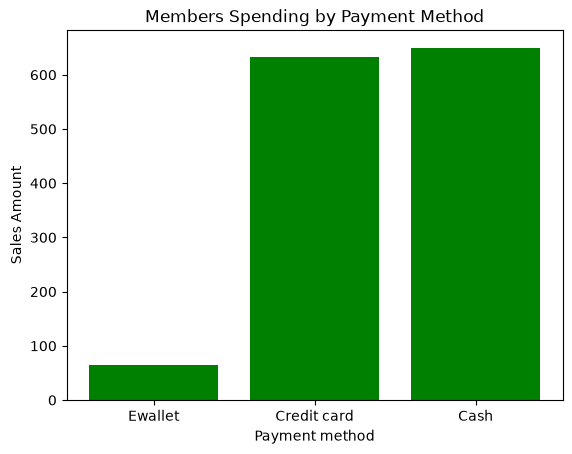

In [205]:
payment_method = ['Ewallet','Credit card','Cash']
member_spend_pay = [63.9975,633.108,649.299]
#Member spending by payment method:  {'Ewallet': 63.9975, 'Credit card': 633.108, 'Cash': 649.299}
#Normal spending by payment method:  {'Cash': 69.111, 'Credit card': 296.94, 'Ewallet': 1022.49}
plt.bar(payment_method,member_spend_pay, color = "green")
plt.xlabel("Payment method")
plt.ylabel("Sales Amount")
plt.title("Members Spending by Payment Method")
plt.show()

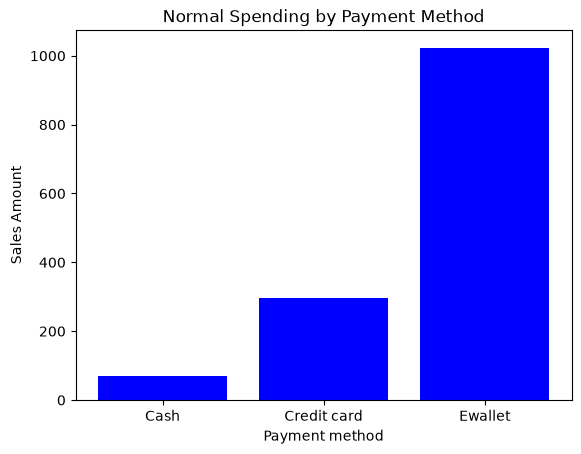

In [206]:
payment_method = ['Cash','Credit card','Ewallet']
member_spend_pay = [69.111, 296.94,1022.49]
#Member spending by payment method:  {'Ewallet': 63.9975, 'Credit card': 633.108, 'Cash': 649.299}
#Normal spending by payment method:  {'Cash': 69.111, 'Credit card': 296.94, 'Ewallet': 1022.49}
plt.bar(payment_method,member_spend_pay, color = "blue")
plt.xlabel("Payment method")
plt.ylabel("Sales Amount")
plt.title("Normal Spending by Payment Method")
plt.show()

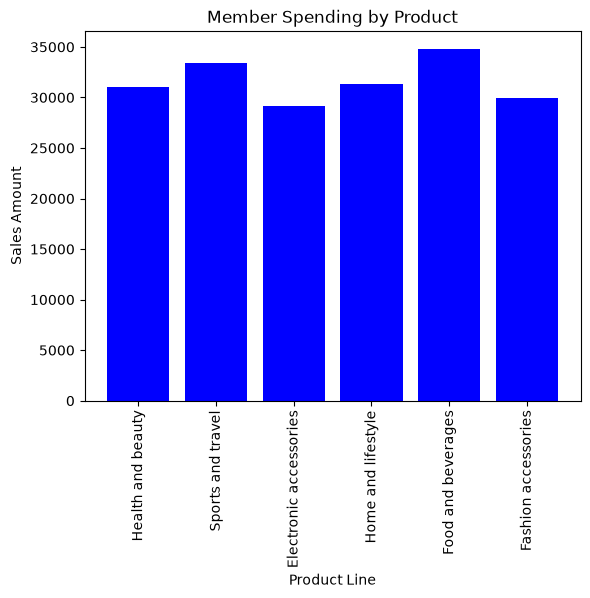

In [213]:
#total member sales by product:  {'Health and beauty': 31036.824, 'Sports and travel': 33396.950999999994, 'Electronic accessories': 29194.7565, 'Home and lifestyle': 31317.279000000006, 'Food and beverages': 34822.38899999999, 'Fashion accessories': 29926.5645}
#$Total normal sales by product:  {'Electronic accessories': 25142.775, 'Home and lifestyle': 22544.634000000005, 'Fashion accessories': 24379.330500000004, 'Sports and travel': 21725.875500000002, 'Health and beauty': 18156.914999999997, 'Food and beverages': 21322.454999999987}

product = ['Health and beauty','Sports and travel','Electronic accessories','Home and lifestyle','Food and beverages','Fashion accessories']
amount = [31036.824, 33396.950999999994,29194.7565,31317.279000000006,34822.38899999999, 29926.5645]

plt.bar(product,amount, color = "blue")
plt.xlabel("Product Line")
plt.xticks(rotation = "vertical")
plt.ylabel("Sales Amount")
plt.title("Member Spending by Product")
plt.show()


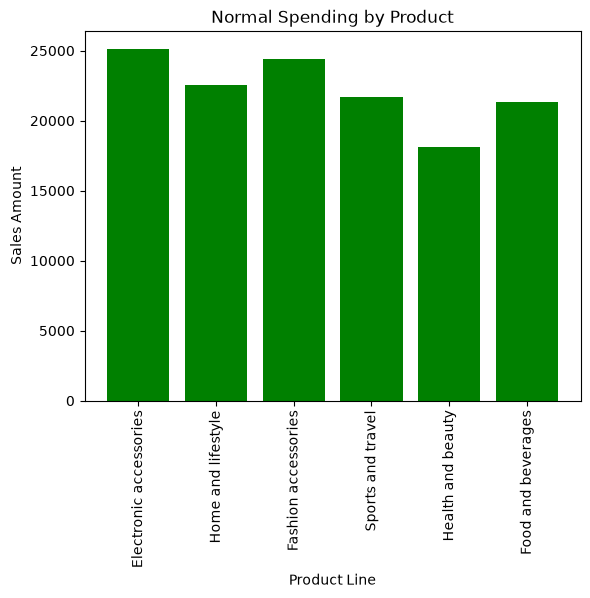

In [214]:
#total member sales by product:  {'Health and beauty': 31036.824, 'Sports and travel': 33396.950999999994, 'Electronic accessories': 29194.7565, 'Home and lifestyle': 31317.279000000006, 'Food and beverages': 34822.38899999999, 'Fashion accessories': 29926.5645}
#$Total normal sales by product:  {'Electronic accessories': 25142.775, 'Home and lifestyle': 22544.634000000005, 'Fashion accessories': 24379.330500000004, 'Sports and travel': 21725.875500000002, 'Health and beauty': 18156.914999999997, 'Food and beverages': 21322.454999999987}

product = ['Electronic accessories','Home and lifestyle','Fashion accessories','Sports and travel','Health and beauty','Food and beverages']
amount = [25142.775, 22544.634, 24379.330,21725.875,18156.914, 21322.454]

plt.bar(product,amount, color = "green")
plt.xlabel("Product Line")
plt.xticks(rotation = "vertical")
plt.ylabel("Sales Amount")
plt.title("Normal Spending by Product")
plt.show()


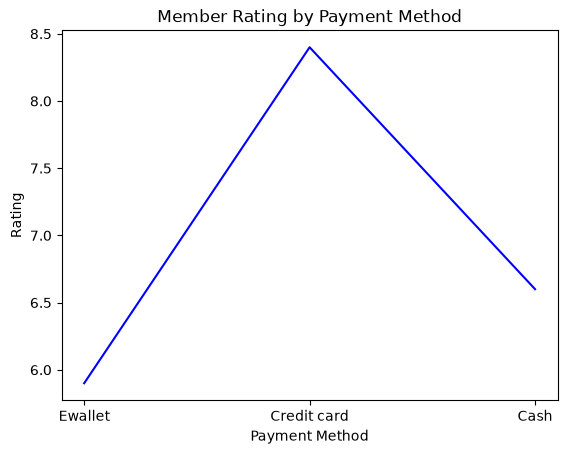

In [216]:
#Member rating by payment method:  {'Ewallet': 5.9, 'Credit card': 8.4, 'Cash': 6.6}
#Normal rating by payment method:  {'Cash': 4.1, 'Credit card': 4.5, 'Ewallet': 4.4}
payment_method = ['Ewallet', 'Credit card', 'Cash']
rating = [5.9,8.4,6.6]

plt.plot(payment_method,rating, color = "blue")
plt.xlabel("Payment Method")
plt.ylabel("Rating")
plt.title("Member Rating by Payment Method")
plt.show()

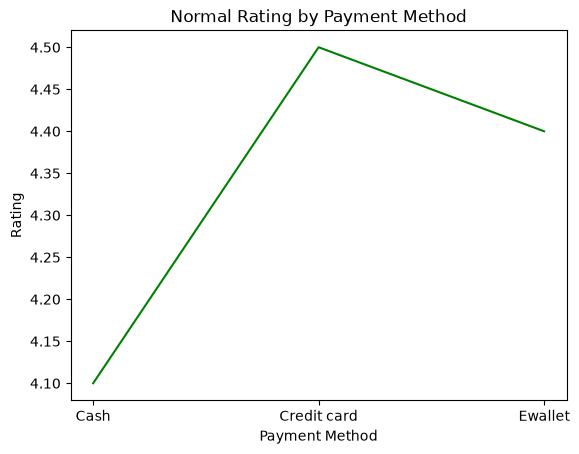

In [217]:
#Member rating by payment method:  {'Ewallet': 5.9, 'Credit card': 8.4, 'Cash': 6.6}
#Normal rating by payment method:  {'Cash': 4.1, 'Credit card': 4.5, 'Ewallet': 4.4}
payment_method = ['Cash', 'Credit card', 'Ewallet']
rating = [4.1, 4.5, 4.4]

plt.plot(payment_method,rating, color = "green")
plt.xlabel("Payment Method")
plt.ylabel("Rating")
plt.title("Normal Rating by Payment Method")
plt.show()